In [ ]:
import numpy as np 
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# Data Loading

In [2]:
df=pd.read_csv(r'C:\Users\devan\OneDrive\Documents\Clickbait classification\clickbait_title_classification.csv')
df

,title,clickbait
0,""".asia"" domain applications near 300,000 on op...",0
1,"""1 Indian + 1 Indian = Unrelatable"": Televisio...",1
2,"""7th Heaven"" television series comes to an end",0
3,"""Arm Glow"" Is Your New Life Goal, Thanks To Lu...",1
4,"""Beans Memes"" Is The Only Twitter Account That...",1
...,...,...
31995,"Íngrid Betancourt and others rescued, says Col...",0
31996,Íngrid Betancourt returns to France,0
31997,‘Twin Towers’ warship set to enter New York,0
31998,"“Dr Death” Steve Williams, American profession...",0


# Text to vector for model fitting

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

print(df['clickbait'].value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    df['title'], df['clickbait'], test_size=0.2, random_state=42
)

vectorizer = TfidfVectorizer(stop_words='english', max_features=10000, ngram_range=(1,2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = XGBClassifier( eval_metric='logloss', random_state=42)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


clickbait
0    16001
1    15999
Name: count, dtype: int64
Accuracy: 0.879375
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.96      0.89      3193
           1       0.95      0.80      0.87      3207

    accuracy                           0.88      6400
   macro avg       0.89      0.88      0.88      6400
weighted avg       0.89      0.88      0.88      6400



# Box-plot

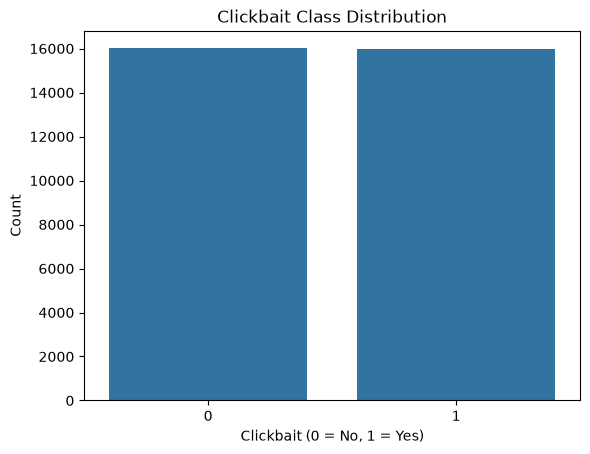

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='clickbait', data=df)
plt.title("Clickbait Class Distribution")
plt.xlabel("Clickbait (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


# Confusion Matrix

Confusion matrix:
 [[3082  111]
 [ 205 3002]]


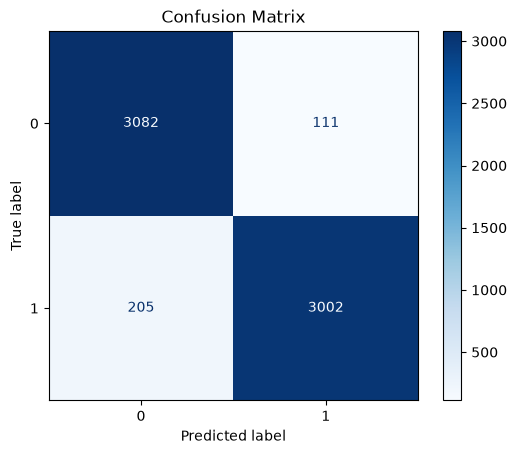

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
print(f'Confusion matrix:\n {cm}')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()


# Length vs Clickbait Classification

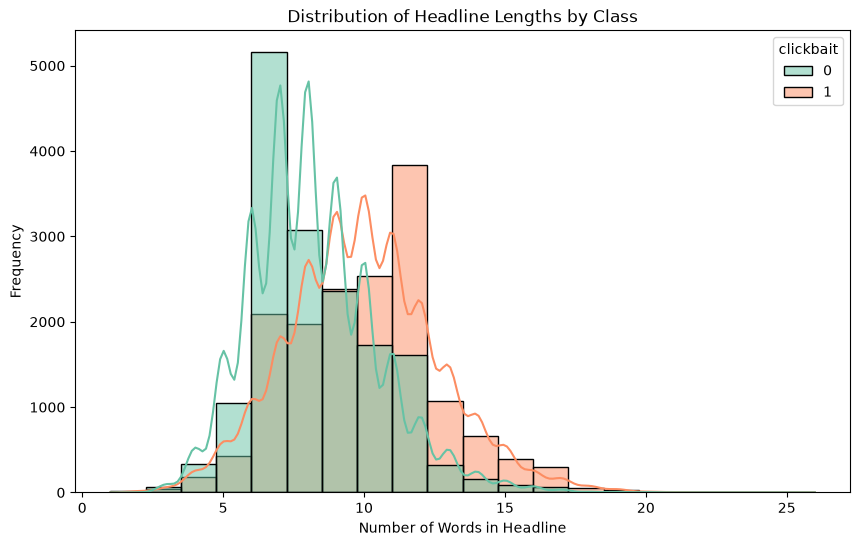

In [6]:
import seaborn as sns

df['length'] = df['title'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10,6))
sns.histplot(data=df, x='length', hue='clickbait', bins=20, kde=True, palette='Set2')
plt.title("Distribution of Headline Lengths by Class")
plt.xlabel("Number of Words in Headline")
plt.ylabel("Frequency")
plt.show()


As expected longer length is more suspected to be Clickbait 